## Welcome to my Data Analysis Project!
## In this project i have evaluated and analysed a personal Goodreads data

In [1]:
import pandas as pd          # For handling data (like Excel but in Python) 
import numpy as np           # For math and numbers
import matplotlib.pyplot as plt  # For creating charts
import seaborn as sns        # For beautiful visualizations

# Let's confirm they all loaded
print("Pandas imported successfully!")
print("Numpy imported successfully!")  
print("Matplotlib imported successfully!")
print("Seaborn imported successfully!")
print("\nAll libraries loaded! Ready to analyze data!")

Pandas imported successfully!
Numpy imported successfully!
Matplotlib imported successfully!
Seaborn imported successfully!

All libraries loaded! Ready to analyze data!


In [2]:
import os
print("Files in this folder are:\n")
for file in os.listdir():
    print(f" . {file} ")

Files in this folder are:

 . .git 
 . .gitignore 
 . .ipynb_checkpoints 
 . .venv 
 . Charts 
 . Data 
 . Goodreads_analysis.ipynb 
 . Readme.md 
 . Readme_DE.md 
 . requirements.txt 


In [3]:
DATA_PATH = os.environ.get("GOODREADS_CSV", "Data/sample_goodreads_library.csv")
df = pd.read_csv(DATA_PATH)
print(f"Total number of books you have : {len(df)}")
print(f"Total number of columns (data fields) : {len(df.columns)}")

Total number of books you have : 341
Total number of columns (data fields) : 24


In [4]:
df.head(10)

,Book Id,Title,Author,Author l-f,Additional Authors,ISBN,ISBN13,My Rating,Average Rating,Publisher,...,Date Read,Date Added,Bookshelves,Bookshelves with positions,Exclusive Shelf,My Review,Spoiler,Private Notes,Read Count,Owned Copies
0,1,Book 001,Sarah J. Maas,"Maas, Sarah J.","Heinrich Koop, Franca Fritz",NaN,NaN,0,4.45,dtv,...,NaN,2026/03/20,currently-reading,currently-reading (#3),currently-reading,NaN,NaN,NaN,1,0
1,2,Book 002,Sarah J. Maas,"Maas, Sarah J.",Anne Brauner,NaN,NaN,3,3.71,dtv Verlagsgesellschaft,...,2026/03/17,2026/03/16,NaN,NaN,read,NaN,NaN,NaN,1,0
2,3,Book 003,Sarah J. Maas,"Maas, Sarah J.",NaN,NaN,NaN,5,4.46,dtv,...,2026/03/16,2026/03/12,NaN,NaN,read,NaN,NaN,NaN,1,0
3,4,Book 004,Olivie Blake,"Blake, Olivie",NaN,NaN,NaN,2,2.84,FISCHER E-Books,...,2025/08/05,2025/05/11,did-not-finish,did-not-finish (#6),did-not-finish,NaN,NaN,NaN,1,0
4,5,Book 005,Laurie Forest,"Forest, Laurie",Freya Rall,NaN,NaN,2,4.10,foliant Verlag,...,NaN,2025/08/07,did-not-finish,did-not-finish (#5),did-not-finish,NaN,NaN,NaN,0,0
5,6,Book 006,Sebastian Fitzek,"Fitzek, Sebastian",NaN,NaN,NaN,0,3.89,Bastei Lübbe,...,NaN,2025/08/17,did-not-finish,did-not-finish (#4),did-not-finish,NaN,NaN,NaN,0,0
6,7,Book 007,R.F. Kuang,"Kuang, R.F.","Heide Franck, Alexandra Jordan",NaN,NaN,0,4.14,Eichborn,...,NaN,2025/08/25,did-not-finish,did-not-finish (#3),did-not-finish,NaN,NaN,NaN,0,0
7,8,Book 008,Chimamanda Ngozi Adichie,"Adichie, Chimamanda Ngozi","Jan Schönherr, Asal Dardan",NaN,NaN,2,3.78,FISCHER E-Books,...,NaN,2025/09/29,did-not-finish,did-not-finish (#2),did-not-finish,NaN,NaN,NaN,0,0
8,9,Book 009,Mona Awad,"Awad, Mona",Elena Helfrecht,NaN,NaN,0,3.45,Festa Verlag,...,NaN,2026/02/03,did-not-finish,did-not-finish (#1),did-not-finish,NaN,NaN,NaN,0,0
9,10,Book 010,Sarah J. Maas,"Maas, Sarah J.",Alexandra Ernst,NaN,NaN,5,4.63,dtv Verlag,...,2026/03/12,2026/03/08,NaN,NaN,read,NaN,NaN,NaN,1,0


In [5]:
print("Data Overview")
print("="*50)
print(f"Total books: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"\n Data Types and Missing Values:")
print("-" * 50)

# This shows each column, its type, and how many values it has
df.info()


Data Overview
Total books: 341
Total columns: 24

 Data Types and Missing Values:
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 341 entries, 0 to 340
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Book Id                     341 non-null    int64  
 1   Title                       341 non-null    str    
 2   Author                      341 non-null    str    
 3   Author l-f                  341 non-null    str    
 4   Additional Authors          150 non-null    str    
 5   ISBN                        0 non-null      float64
 6   ISBN13                      0 non-null      float64
 7   My Rating                   341 non-null    int64  
 8   Average Rating              341 non-null    float64
 9   Publisher                   331 non-null    str    
 10  Binding                     340 non-null    str    
 11  Number of Pages            

In [6]:
df[['My Rating', 'Average Rating', 'Read Count']].describe()

,My Rating,Average Rating,Read Count
count,341.000000,341.000000,341.000000
mean,3.096774,3.999765,0.862170
std,1.858056,0.329796,0.377772
min,0.000000,2.670000,0.000000
25%,2.000000,3.790000,1.000000
50%,4.000000,4.020000,1.000000
75%,5.000000,4.250000,1.000000
max,5.000000,4.630000,2.000000


In [7]:
print("CHECKING KEY COLUMNS :")
print("="*50)
print(f"Total no. of books : {len(df)}")
books_with_actual_rating = (df['My Rating'] > 0).sum()
print(f"Books with Ratings : {books_with_actual_rating}")
books_with_no_ratings = (df['My Rating'] == 0).sum()
print(f"Books with no ratings : {books_with_no_ratings}")
books_with_date = df['Date Read'].notna().sum()
print(f"Books with read date : {books_with_date}")
books_with_pages = df['Number of Pages'].notna().sum()
print(f"Books with page count : {books_with_pages}")


CHECKING KEY COLUMNS :
Total no. of books : 341
Books with Ratings : 265
Books with no ratings : 76
Books with read date : 139
Books with page count : 338


## Now, i will extract "Read Books" data and perform different analyses.


In [8]:
print("CHECKING BOOK SHELVES:")
print("="*50)
print("\n looking for shelf info...")
if 'Exclusive Shelf' in df.columns:
    print("Exclusive Shlef found")
    print("Shelf breakdown:")
    print(df['Exclusive Shelf'].value_counts())
else:
    print("Did not found Exclusive Shelf")
    print("\n Available Columns :")
    for col in df.columns:
        if 'shelf' in col.lower() or 'status' in col.lower():
            print(f" . {col}")

CHECKING BOOK SHELVES:

 looking for shelf info...
Exclusive Shlef found
Shelf breakdown:
Exclusive Shelf
read                 286
to-read               46
did-not-finish         6
currently-reading      3
Name: count, dtype: int64


In [9]:
books_read_count = (df['Exclusive Shelf'] == 'read').sum()
print("comparing some quantities :")
print("="*100)
print(f"\n Total no. of books read are {books_read_count}")
print(f"\n Total no. of rated books are {books_with_actual_rating}")

comparing some quantities :

 Total no. of books read are 286

 Total no. of rated books are 265


In [10]:
print(df['My Rating'].value_counts())
print(f"Total Books read are {books_read_count}")

My Rating
4    101
5     91
0     76
3     54
2     16
1      3
Name: count, dtype: int64
Total Books read are 286


In [11]:
Ratings = (df['My Rating'].value_counts())
four_stars = Ratings.get(4,0)
print(f"no of 4 ratings are {four_stars}")
print(f"Total Books read are {books_read_count}")
    
    

no of 4 ratings are 101
Total Books read are 286


In [12]:
# Trying different method to produce the same result for "four_stars"
four_stars = len(df[df['My Rating'] == 4])  
print(f" You have rated books with 4 stars {four_stars} times")

 You have rated books with 4 stars 101 times


In [13]:
# Recreate read_books as a DataFrame
print("Recreating read_books properly...")
print("=" * 50)

read_books = df[df['Exclusive Shelf'] == 'read'].copy()

print(f"Type: {type(read_books)}")
print(f"Number of books: {books_read_count}")
print(f"\nFirst 3 rows:")
print(read_books.head(3))

Recreating read_books properly...
Type: <class 'pandas.DataFrame'>
Number of books: 286

First 3 rows:
   Book Id     Title         Author      Author l-f Additional Authors  ISBN  \
1        2  Book 002  Sarah J. Maas  Maas, Sarah J.       Anne Brauner   NaN   
2        3  Book 003  Sarah J. Maas  Maas, Sarah J.                NaN   NaN   
9       10  Book 010  Sarah J. Maas  Maas, Sarah J.    Alexandra Ernst   NaN   

   ISBN13  My Rating  Average Rating                Publisher  ...  \
1     NaN          3            3.71  dtv Verlagsgesellschaft  ...   
2     NaN          5            4.46                      dtv  ...   
9     NaN          5            4.63               dtv Verlag  ...   

    Date Read  Date Added  Bookshelves  Bookshelves with positions  \
1  2026/03/17  2026/03/16          NaN                         NaN   
2  2026/03/16  2026/03/12          NaN                         NaN   
9  2026/03/12  2026/03/08          NaN                         NaN   

  Exclusive Sh

In [14]:
print(read_books['Date Read'].head(10))

1     2026/03/17
2     2026/03/16
9     2026/03/12
10    2026/03/07
11    2026/03/06
12    2026/03/03
13    2026/02/22
14    2026/02/18
16    2026/02/14
18    2026/02/15
Name: Date Read, dtype: str


In [15]:
print(type(read_books))

<class 'pandas.DataFrame'>


In [16]:
print(read_books['Date Read'].dtype)

str


In [17]:
print("Now converting the date into right format")
print("="*100)
read_books['Date Read'] = pd.to_datetime(read_books['Date Read'], errors = 'coerce')
print(f"Sample: {read_books['Date Read'].iloc[0]}")
print(f"\n Now the newly converted type is : {read_books['Date Read'].dtype}")

Now converting the date into right format
Sample: 2026-03-17 00:00:00

 Now the newly converted type is : datetime64[us]


In [18]:
print(f"First five dates : \n{read_books['Date Read'].iloc[0:5]}")

First five dates : 
1    2026-03-17
2    2026-03-16
9    2026-03-12
10   2026-03-07
11   2026-03-06
Name: Date Read, dtype: datetime64[us]


In [19]:
read_books['Year']= read_books['Date Read'].dt.year
print(read_books['Year'].head(10))

1     2026.0
2     2026.0
9     2026.0
10    2026.0
11    2026.0
12    2026.0
13    2026.0
14    2026.0
16    2026.0
18    2026.0
Name: Year, dtype: float64


In [20]:
# Extract year first, then convert
read_books['Year'] = read_books['Date Read'].dt.year.astype('Int64')

print("Year extracted and converted correctly!")
print(f"Data type: {read_books['Year'].dtype}")
print("\nFirst 10 years:")
print(read_books['Year'].head(10))

Year extracted and converted correctly!
Data type: Int64

First 10 years:
1     2026
2     2026
9     2026
10    2026
11    2026
12    2026
13    2026
14    2026
16    2026
18    2026
Name: Year, dtype: Int64


In [21]:
print("Counting books per year")
print("="*50)
books_per_year = read_books['Year'].value_counts().sort_index()
print(f"Books read per year are : {books_per_year}")
print(f"\nMost productive year : {books_per_year.idxmax()} with {books_per_year.max()}")
print(f"Least productive year : {books_per_year.idxmin()} with {books_per_year.min()}")

Counting books per year
Books read per year are : Year
2015    23
2016     1
2025    97
2026    17
Name: count, dtype: Int64

Most productive year : 2025 with 97
Least productive year : 2016 with 1


Creating first Chart


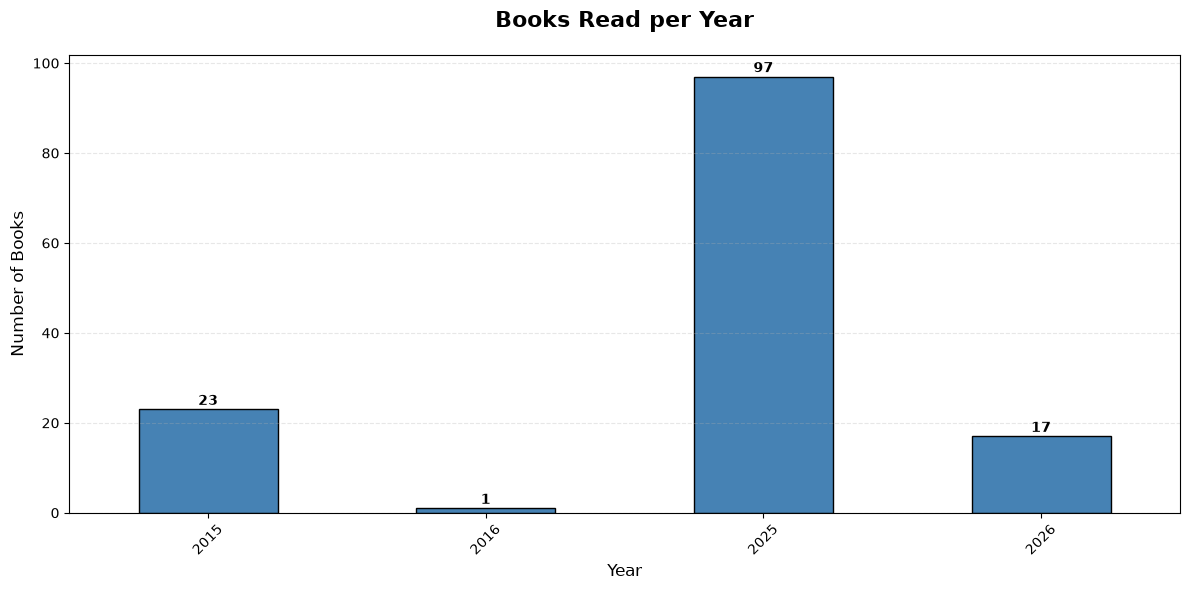

In [22]:
print("Creating first Chart")
print("="*100)
plt.figure(figsize=(12, 6))  #create a figure
books_per_year.plot(kind='bar', color='steelblue', edgecolor='black')   #creating a chart
plt.title('Books Read per Year', fontsize=16, fontweight='bold', pad=20)  # adding labels
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Books', fontsize=12)

plt.xticks(rotation=45)

plt.grid(axis='y', alpha=0.3, linestyle='--')  #adding grid

for i, v in enumerate(books_per_year):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold', fontsize=10)  #adding text on bars

# Adjust layout
plt.tight_layout()

plt.savefig("Charts/books_per_year.png")

# Show the chart!
plt.show()



### Analysis on above chart : 

 - The year with the most books read is 2025 with 97 books read
 - The year with the least books read is 2016 with 1
 - Gap between 2016 to 2025. Probably not read any books or did not updated Goodreads

In [23]:
print("Counting books read per month")
print("="*50)

read_books['Year'] = read_books['Date Read'].dt.year.astype('Int64')
read_books['Month'] = read_books['Date Read'].dt.month.astype('Int64')
read_books['Month_Name'] = read_books['Date Read'].dt.month_name()

#create a year-month grouping
read_books['Year_Month'] = read_books['Date Read'].dt.to_period('M')

print("\n First 10 rows with year and month")
print(read_books[['Date Read', 'Year', 'Month', 'Month_Name', 'Year_Month']].head(10))

Counting books read per month

 First 10 rows with year and month
    Date Read  Year  Month Month_Name Year_Month
1  2026-03-17  2026      3      March    2026-03
2  2026-03-16  2026      3      March    2026-03
9  2026-03-12  2026      3      March    2026-03
10 2026-03-07  2026      3      March    2026-03
11 2026-03-06  2026      3      March    2026-03
12 2026-03-03  2026      3      March    2026-03
13 2026-02-22  2026      2   February    2026-02
14 2026-02-18  2026      2   February    2026-02
16 2026-02-14  2026      2   February    2026-02
18 2026-02-15  2026      2   February    2026-02


In [24]:
print("Counting books per month")
print("="*50)

books_per_month = read_books.groupby('Year_Month').size()
print(books_per_month.head(10))
print(len(books_per_month))

Counting books per month
Year_Month
2015-01    1
2015-02    2
2015-03    5
2015-04    3
2015-06    2
2015-07    2
2015-08    2
2015-09    3
2015-10    3
2016-01    1
Freq: M, dtype: int64
25


In [25]:
print("\nCOUNTING BOOKS PER MONTH")
print("=" * 50)

# Count books per year-month
books_per_month = read_books.groupby('Year_Month').size()

print("\nBooks per month:")
print(books_per_month.head(15))  # Show first 15 months

print(f"\nTotal months with reading data: {len(books_per_month)}")
print(f"Most productive month: {books_per_month.idxmax()} with {books_per_month.max()} books")
print(f"Quietest month: {books_per_month.idxmin()} with {books_per_month.min()} books")


COUNTING BOOKS PER MONTH

Books per month:
Year_Month
2015-01    1
2015-02    2
2015-03    5
2015-04    3
2015-06    2
2015-07    2
2015-08    2
2015-09    3
2015-10    3
2016-01    1
2025-01    3
2025-02    8
2025-03    4
2025-04    9
2025-05    9
Freq: M, dtype: int64

Total months with reading data: 25
Most productive month: 2025-07 with 12 books
Quietest month: 2015-01 with 1 books


## Extracting data for the most productive year i.e, 2025 and creating a chart of monthly stats

In [26]:
books_in_25 = read_books[read_books['Year'] == 2025][['Book Id', 'Title', 'Year', 'Month', 'Date Read']]

print("Books read in the year 2025")
print("="*50)
print(books_in_25.head(10))

Books read in the year 2025
    Book Id     Title  Year  Month  Date Read
29       30  Book 030  2025     12 2025-12-29
32       33  Book 033  2025     12 2025-12-28
34       35  Book 035  2025     12 2025-12-20
35       36  Book 036  2025     12 2025-12-19
37       38  Book 038  2025     12 2025-12-17
38       39  Book 039  2025     12 2025-12-14
39       40  Book 040  2025     12 2025-12-13
40       41  Book 041  2025     12 2025-12-09
42       43  Book 043  2025     12 2025-12-05
43       44  Book 044  2025     12 2025-12-04


In [27]:
import calendar  

books_in_25['Month'] = books_in_25['Date Read'].dt.month

count = books_in_25['Month'].value_counts().sort_index().reset_index()


count['Month'] = count['Month'].apply(lambda x: calendar.month_name[x])   # to change the months from numbers to month names
print(count)

count.columns = ['Month', 'Count']


        Month  count
0     January      3
1    February      8
2       March      4
3       April      9
4         May      9
5        June     10
6        July     12
7      August     11
8   September      5
9     October      6
10   November      8
11   December     12


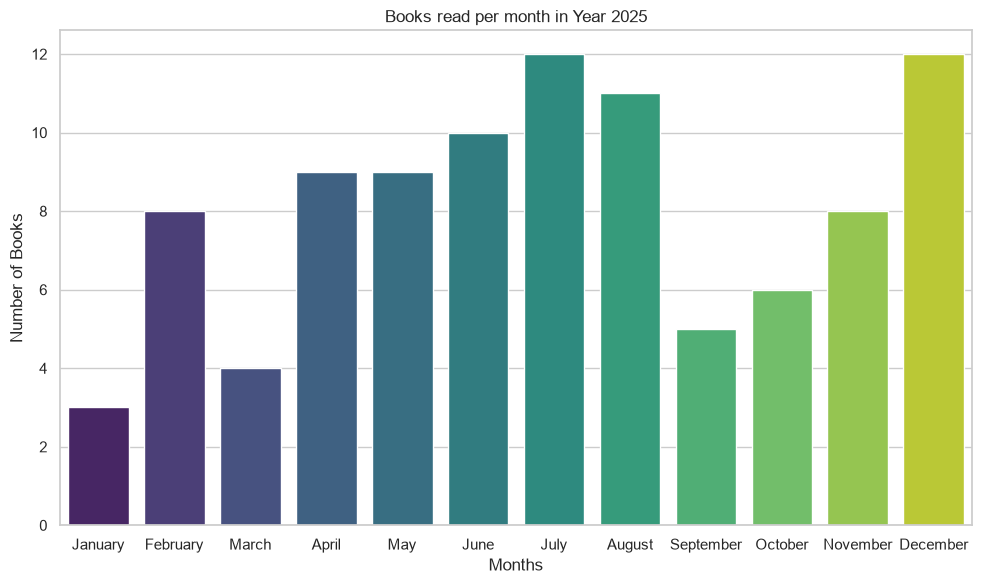

In [28]:
sns.set(style="whitegrid")

plt.figure(figsize=(10,6))

sns.barplot( 
    data = count,
    x = 'Month',
    y = 'Count',
    hue = 'Month',
    palette = 'viridis',
    legend = False
)

plt.title("Books read per month in Year 2025")
plt.xlabel("Months")
plt.ylabel("Number of Books")

plt.xticks(rotation = 0)
plt.tight_layout()
plt.savefig("Charts/Books_per_month_2025.png")
plt.show()

### Key Insights from the above chart:

   - Reading peaked in July and December
   - Very few books were read in January and March


 ## In next phase, i worked upon null values.
  - Found null values in column 'Publisher' and updated them

In [29]:
df.isnull()

,Book Id,Title,Author,Author l-f,Additional Authors,ISBN,ISBN13,My Rating,Average Rating,Publisher,...,Date Read,Date Added,Bookshelves,Bookshelves with positions,Exclusive Shelf,My Review,Spoiler,Private Notes,Read Count,Owned Copies
0,False,False,False,False,False,True,True,False,False,False,...,True,False,False,False,False,True,True,True,False,False
1,False,False,False,False,False,True,True,False,False,False,...,False,False,True,True,False,True,True,True,False,False
2,False,False,False,False,True,True,True,False,False,False,...,False,False,True,True,False,True,True,True,False,False
3,False,False,False,False,True,True,True,False,False,False,...,False,False,False,False,False,True,True,True,False,False
4,False,False,False,False,False,True,True,False,False,False,...,True,False,False,False,False,True,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336,False,False,False,False,False,True,True,False,False,False,...,True,False,True,True,False,True,True,True,False,False
337,False,False,False,False,False,True,True,False,False,False,...,True,False,True,True,False,True,True,True,False,False
338,False,False,False,False,True,True,True,False,False,False,...,True,False,True,True,False,True,True,True,False,False
339,False,False,False,False,True,True,True,False,False,False,...,True,False,True,True,False,True,True,True,False,False


In [30]:
df.isnull().any().any()  # Returns True if ANY null exists

np.True_

In [31]:
df[df.isnull().any(axis=1)]

,Book Id,Title,Author,Author l-f,Additional Authors,ISBN,ISBN13,My Rating,Average Rating,Publisher,...,Date Read,Date Added,Bookshelves,Bookshelves with positions,Exclusive Shelf,My Review,Spoiler,Private Notes,Read Count,Owned Copies
0,1,Book 001,Sarah J. Maas,"Maas, Sarah J.","Heinrich Koop, Franca Fritz",NaN,NaN,0,4.45,dtv,...,NaN,2026/03/20,currently-reading,currently-reading (#3),currently-reading,NaN,NaN,NaN,1,0
1,2,Book 002,Sarah J. Maas,"Maas, Sarah J.",Anne Brauner,NaN,NaN,3,3.71,dtv Verlagsgesellschaft,...,2026/03/17,2026/03/16,NaN,NaN,read,NaN,NaN,NaN,1,0
2,3,Book 003,Sarah J. Maas,"Maas, Sarah J.",NaN,NaN,NaN,5,4.46,dtv,...,2026/03/16,2026/03/12,NaN,NaN,read,NaN,NaN,NaN,1,0
3,4,Book 004,Olivie Blake,"Blake, Olivie",NaN,NaN,NaN,2,2.84,FISCHER E-Books,...,2025/08/05,2025/05/11,did-not-finish,did-not-finish (#6),did-not-finish,NaN,NaN,NaN,1,0
4,5,Book 005,Laurie Forest,"Forest, Laurie",Freya Rall,NaN,NaN,2,4.10,foliant Verlag,...,NaN,2025/08/07,did-not-finish,did-not-finish (#5),did-not-finish,NaN,NaN,NaN,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336,337,Book 337,L.J. Smith,"Smith, L.J.",Ingrid Gross,NaN,NaN,0,3.44,cbt,...,NaN,2014/03/06,NaN,NaN,read,NaN,NaN,NaN,1,0
337,338,Book 338,Michelle Harrison,"Harrison, Michelle",Martin Baresch,NaN,NaN,0,4.24,Loewe Verlag,...,NaN,2014/03/06,NaN,NaN,read,NaN,NaN,NaN,1,0
338,339,Book 339,Inge Löhnig,"Löhnig, Inge",NaN,NaN,NaN,0,3.65,Arena,...,NaN,2014/03/06,NaN,NaN,read,NaN,NaN,NaN,1,0
339,340,Book 340,Hilmar Bender,"Bender, Hilmar",NaN,NaN,NaN,0,2.67,Ubooks,...,NaN,2014/03/06,NaN,NaN,read,NaN,NaN,NaN,1,0


In [32]:
df[df['Publisher'].isnull()]

,Book Id,Title,Author,Author l-f,Additional Authors,ISBN,ISBN13,My Rating,Average Rating,Publisher,...,Date Read,Date Added,Bookshelves,Bookshelves with positions,Exclusive Shelf,My Review,Spoiler,Private Notes,Read Count,Owned Copies
43,44,Book 044,Victoria May,"May, Victoria",NaN,NaN,NaN,4,3.75,NaN,...,2025/12/04,2025/12/03,NaN,NaN,read,NaN,NaN,NaN,1,0
48,49,Book 049,Caroline Peckham,"Peckham, Caroline",Susanne Valenti,NaN,NaN,2,4.09,NaN,...,2025/11/23,2025/08/03,NaN,NaN,read,NaN,NaN,NaN,1,0
98,99,Book 099,Caroline Peckham,"Peckham, Caroline",Susanne Valenti,NaN,NaN,2,4.26,NaN,...,2025/06/26,2025/06/17,NaN,NaN,read,NaN,NaN,NaN,1,0
99,100,Book 100,Patrick C. Harrison III,"III, Patrick C. Harrison",NaN,NaN,NaN,3,3.00,NaN,...,2025/06/23,2025/06/23,NaN,NaN,read,NaN,NaN,NaN,1,0
108,109,Book 109,John Marrs,"Marrs, John",NaN,NaN,NaN,0,4.09,NaN,...,NaN,2025/06/13,to-read,to-read (#23),to-read,NaN,NaN,NaN,0,0
139,140,Book 140,J.S. Wonda,"Wonda, J.S.",NaN,NaN,NaN,3,3.75,NaN,...,2025/04/25,2025/04/24,NaN,NaN,read,NaN,NaN,NaN,1,0
140,141,Book 141,J.S. Wonda,"Wonda, J.S.",NaN,NaN,NaN,4,3.49,NaN,...,2025/04/22,2025/04/21,NaN,NaN,read,NaN,NaN,NaN,1,0
145,146,Book 146,Olivie Blake,"Blake, Olivie",NaN,NaN,NaN,5,3.54,NaN,...,2025/04/17,2025/03/07,NaN,NaN,read,NaN,NaN,NaN,1,0
151,152,Book 152,Lauren Roberts,"Roberts, Lauren",NaN,NaN,NaN,0,4.15,NaN,...,NaN,2025/03/26,to-read,to-read (#5),to-read,NaN,NaN,NaN,0,0
243,244,Book 244,Phillip P. Peterson,"Peterson, Phillip P.",NaN,NaN,NaN,4,4.09,NaN,...,2015/10/01,2015/11/02,NaN,NaN,read,NaN,NaN,NaN,1,0


In [33]:
df['Publisher'].isnull().sum()

np.int64(10)

In [34]:
df[df['Publisher'].isnull()].groupby(['Title', 'Author']).size()

Title     Author                 
Book 044  Victoria May               1
Book 049  Caroline Peckham           1
Book 099  Caroline Peckham           1
Book 100  Patrick C. Harrison III    1
Book 109  John Marrs                 1
Book 140  J.S. Wonda                 1
Book 141  J.S. Wonda                 1
Book 146  Olivie Blake               1
Book 152  Lauren  Roberts            1
Book 244  Phillip P. Peterson        1
dtype: int64

 ## I decided to use 'Open Library' API to match books with Goodreads to possibly find and update missing 'Publisher' column

In [35]:
import requests

def Get_Publishers(Title, Author):
   try:
       url= "https://openlibrary.org/search.json"
       params= {"title": Title, "author": Author}

       response= requests.get(url, params=params)
       data = response.json()
    
       print(response.status_code)
       print("It Worked!")
       return data
      

   except Exception as e:
       print("Sorry. It did not worked:", e)
       return None
      


    

    

In [36]:
data = Get_Publishers("Harry Potter", "J.K. Rowling")

200
It Worked!


In [37]:
print(type(data))

<class 'dict'>


In [38]:
print(data.keys())

dict_keys(['numFound', 'start', 'numFoundExact', 'num_found', 'documentation_url', 'q', 'offset', 'docs'])


In [39]:
print(data['docs'][10])

{'author_key': ['OL23919A'], 'author_name': ['J. K. Rowling'], 'cover_edition_key': 'OL27279750M', 'cover_height': 475, 'cover_i': 8761929, 'cover_width': 309, 'ebook_access': 'no_ebook', 'edition_count': 11, 'first_publish_year': 1999, 'has_fulltext': False, 'key': '/works/OL8460139W', 'language': ['fre', 'eng'], 'public_scan_b': False, 'series_key': ['OL326110L'], 'series_name': ['Harry Potter'], 'series_position': ['1-4'], 'title': 'Harry Potter (series) 1-4'}


In [40]:
print(data['docs'][1]['author_name'])

['J. K. Rowling']


In [41]:
for i, doc in enumerate(data['docs'][:5]):    # Did not found 'Publisher' in Openlibrary
    title = doc.get('title')
    publisher = doc.get('publisher')
    print(i, title, publisher)

0 Harry Potter and the Philosopher's Stone None
1 Harry Potter and the Chamber of Secrets None
2 Harry Potter and the Deathly Hallows None
3 Harry Potter and the Prisoner of Azkaban None
4 Harry Potter and the Goblet of Fire None


In [42]:
import requests

def search_books_openlibrary(Title, Author):
    try: 
        url = "https://openlibrary.org/search.json"
        param = {'title':Title, 'author': Author}

        response= requests.get(url, params=param)
        data= response.json()

        docs=data.get("docs", [])

        for doc in docs:
            if Author in doc.get("author_name", []):
                found_title= doc.get("title")
                found_author= doc.get("author_name")
                return found_title, found_author
            else:
                print(f"Did not found anything for {title} and {author}!!!")
                return None

    except Exception as e:
        print(f"Error occured : {e}")
        return None
        
            

In [43]:
missing_df= df[df['Publisher'].isnull()]     #here i am checking if the books from Goodreads are even present in the Openlibrary

for idx, row in missing_df.iterrows():
    result = search_books_openlibrary(row['Title'], row['Author'])
    if result:
        found_title, found_author = result
        print(f"Found : {found_title} and {found_author}")
    else:
        print("Sorry, not found")
    

Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


Sorry, not found


## Analysis : 
i could not find a column 'Publisher' in Openlibrary. After researching, i found out that books in Goodreads are self published.




In [44]:
mask = df['Publisher'].isnull()
df.loc[mask, 'Publisher'] = "Self Published"

In [45]:
df[df['Publisher'] == "Self Published"][['Title', 'Author', 'Publisher']] #changed the databse and added the tag "self published" 

,Title,Author,Publisher
43,Book 044,Victoria May,Self Published
48,Book 049,Caroline Peckham,Self Published
98,Book 099,Caroline Peckham,Self Published
99,Book 100,Patrick C. Harrison III,Self Published
108,Book 109,John Marrs,Self Published
139,Book 140,J.S. Wonda,Self Published
140,Book 141,J.S. Wonda,Self Published
145,Book 146,Olivie Blake,Self Published
151,Book 152,Lauren Roberts,Self Published
243,Book 244,Phillip P. Peterson,Self Published


## Creating a chart depicting the authors distributions in Goodreads

In [46]:
df['Publisher'].value_counts().head(20)

Publisher
Carlsen                         21
Blanvalet                       15
King's Hollow                   11
Self Published                  10
cbt                              7
Carlsen Verlag                   6
HarperCollins                    5
Deutscher Taschenbuch Verlag     5
Ravensburger Buchverlag          5
dtv                              4
Adrian & Wimmelbuchverlag        4
Arena                            4
cbt Fantasy                      4
FISCHER E-Books                  3
Bastei Lübbe                     3
Eichborn                         3
Ullstein                         3
Rowohlt                          3
Fischer                          3
Hanser Berlin                    3
Name: count, dtype: int64

In [47]:
df['Author'].value_counts().head(15)

Author
Caroline Peckham      16
J.K. Rowling          13
George R.R. Martin    10
Diana Gabaldon         9
Stephenie Meyer        7
Holly Black            6
L.J. Smith             6
Sarah J. Maas          5
Neal Shusterman        5
Freida McFadden        5
Suzanne Collins        5
Kiera Cass             5
Rick Riordan           5
Ian Ogilvy             5
Simon Beckett          4
Name: count, dtype: int64

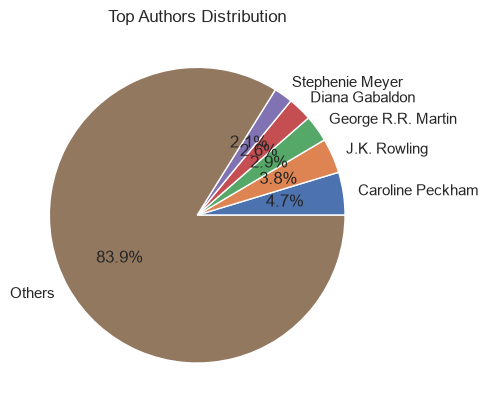

In [48]:
author_counts = df['Author'].value_counts()

top_authors= author_counts.head(5)
others= author_counts.iloc[5:].sum()

import matplotlib.pyplot as plt

pie_data = pd.concat([top_authors, pd.Series([others], index= ["Others"])])

pie_data.plot(kind='pie',autopct= '%1.1f%%')
plt.title("Top Authors Distribution")
plt.ylabel("")
plt.savefig("charts/Top_Authors_Distribution.png")
plt.show()



### Analysis on the above chart (and below) : 
   - The author with the most books in library is Caroline Peckham with 16 books
   - Second author with the most books in library is J.K. Rowling with 13 books



## Chart for number of books per author

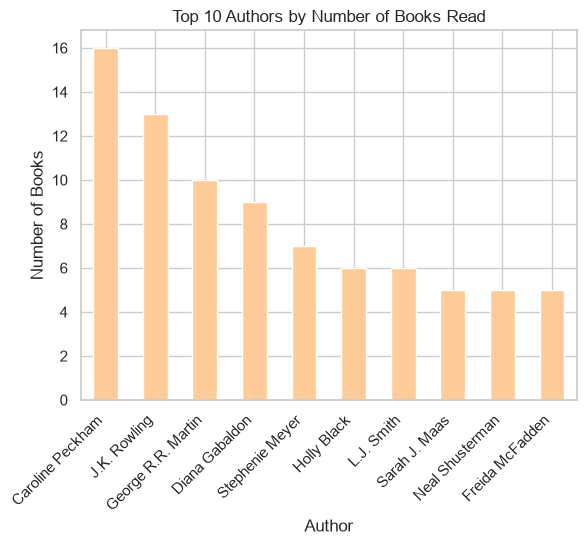

In [49]:
author_counts = df['Author'].value_counts().head(10)

# Plot bar chart
author_counts.plot(kind='bar', color='#ffcc99')
plt.title("Top 10 Authors by Number of Books Read")
plt.xlabel("Author")
plt.ylabel("Number of Books")
plt.xticks(rotation=45, ha='right')
plt.show()


## Creating a chart to depict ratio between Indie authors and Traditional

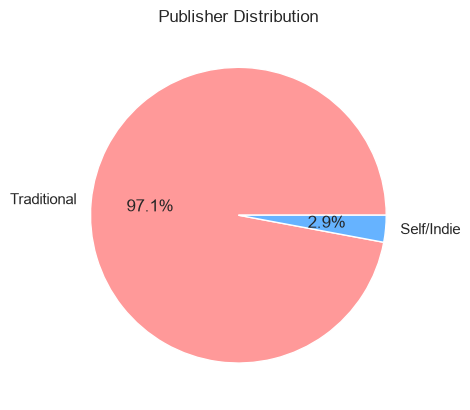

In [50]:
import matplotlib.pyplot as plt

# Make sure we have Publisher_Type
df['Publisher_Type'] = df['Publisher'].apply(lambda x: "Self/Indie" if x == "Self Published" else "Traditional")

# Count values
publisher_counts = df['Publisher_Type'].value_counts()

# Plot pie chart
publisher_counts.plot(kind='pie', autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])
plt.title("Publisher Distribution")
plt.ylabel("")  # remove y-label for cleaner look
plt.savefig("charts/Publisher_Distribution.png")
plt.show()

### Analysis on the above chart: 

    - Traditional publishers tops the chart with 97.1% share
    - Self-Published/Indie shares 2.9% of the library


In [51]:
df.columns

Index(['Book Id', 'Title', 'Author', 'Author l-f', 'Additional Authors',
       'ISBN', 'ISBN13', 'My Rating', 'Average Rating', 'Publisher', 'Binding',
       'Number of Pages', 'Year Published', 'Original Publication Year',
       'Date Read', 'Date Added', 'Bookshelves', 'Bookshelves with positions',
       'Exclusive Shelf', 'My Review', 'Spoiler', 'Private Notes',
       'Read Count', 'Owned Copies', 'Publisher_Type'],
      dtype='str')


## Analysing the binding types

In [52]:
df['Binding']

0           Paperback
1           Paperback
2           Paperback
3      Kindle Edition
4           Hardcover
            ...      
336         Paperback
337         Hardcover
338         Paperback
339         Paperback
340         Paperback
Name: Binding, Length: 341, dtype: str

In [53]:
df['Binding'].value_counts()

Binding
Hardcover                132
Paperback                107
Kindle Edition            87
ebook                      8
Unknown Binding            2
Klappenbroschur            1
Gebundene Ausgabe          1
Mass Market Paperback      1
Audio CD                   1
Name: count, dtype: int64

Total no. of books are : 341
**************************************************


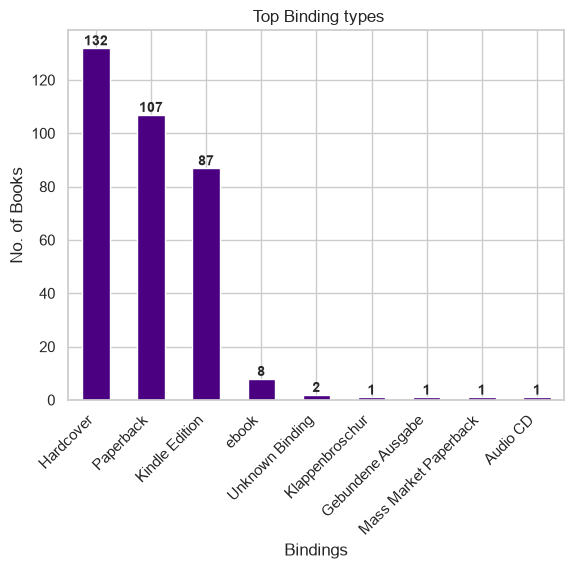

In [54]:
bindings= df['Binding'].value_counts()

print(f"Total no. of books are : {len(df)}")
print("*"*50)

bindings.plot(kind='bar', color = '#4b0082')
plt.title(" Top Binding types")
plt.xlabel("Bindings")
plt.ylabel("No. of Books")
plt.xticks(rotation=45, ha='right')
for i, v in enumerate(bindings):
    plt.text(i, v + 1, str(v), ha='center', fontweight='bold', fontsize=10)  #adding text on bars
plt.savefig("charts/Top_Binding_Types.png")
plt.show()

### Analysis on the above chart :

  - Hardcover books are the most owned bindiing type with 132 books
  - Second most are Paperback with 107 books




## Creating an interactive Scatterd graph to show comparison between 'My Ratings' and 'Average Rating'

In [55]:
df['My Rating'].value_counts()

My Rating
4    101
5     91
0     76
3     54
2     16
1      3
Name: count, dtype: int64

In [56]:
df['Average Rating'].value_counts()

Average Rating
4.27    10
4.16     8
4.03     7
4.09     7
3.75     7
        ..
3.64     1
3.50     1
3.26     1
2.67     1
3.32     1
Name: count, Length: 115, dtype: int64

In [57]:
print("Average Rating:", df['My Rating'].mean())
print("Highest Rating:", df['My Rating'].max())
print("Lowest Rating:", df['My Rating'].min())


Average Rating: 3.096774193548387
Highest Rating: 5
Lowest Rating: 0


In [58]:
import plotly.express as px
import plotly.io as pio


fig = px.scatter(
    df,
    x='Average Rating',
    y='My Rating',
    hover_data=['Title', 'Author'],  # shows title and author on hover
    color='Publisher_Type',          # self-published vs traditional
    size='My Rating',                # optional: bigger dot for higher rating
    title='My Rating vs Average Rating'
)

fig.update_layout(
    xaxis_title='Average Rating (All Users)',
    yaxis_title='My Rating',
    width=800,
    height=600
)
fig.write_html("Charts/Rating_vs_Avg.html", include_plotlyjs="cdn")
fig.show()

### Analysis on the above chart : 

   - depicts that most of 'My Ratings' are similar to the general large audience
   - though some values suggests large differences which is a sign of strong personal opinions on certain books

In [59]:
df['Read Count'].value_counts()

Read Count
1    286
0     51
2      4
Name: count, dtype: int64

In [60]:
df[df['Read Count'] == 2][['Title', 'Author', 'Read Count']]

,Title,Author,Read Count
171,Book 172,Stephenie Meyer,2
174,Book 175,Stephenie Meyer,2
175,Book 176,Stephenie Meyer,2
186,Book 187,Gregory David Roberts,2
